# Proyek Analisis Data: [E-Commerce Public Dataset]
- **Nama:** Muhammad Ridwanansyah Rahman
- **Email:** muh.ridwanansyah.rahman230806@gmail.com
- **ID Dicoding:** DS269B6Y1248

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa yang menghasilkan revenue tertinggi dan terendah selama Januari-Agustus 2018, dan berapa persen kontribusi 5 kategori teratas terhadap total revenue pada periode tersebut, sehingga tim dapat memprioritaskan kategori untuk promosi dan pengelolaan stok?

- **Pertanyaan 2:** Bagaimana distribusi jumlah pelanggan dan persentase total monetary pada setiap segmen RFM selama Januari-Agustus 2018, dan segmen mana yang menyumbang nilai belanja terbesar sehingga dapat diprioritaskan dalam program retensi pelanggan?

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur gaya tampilan visualisasi agar bersih dan rapi
sns.set(style="whitegrid")
print("Library berhasil diimpor!")

Library berhasil diimpor!


## Data Wrangling

### Gathering Data

#### Load df ...

In [2]:
# Memuat seluruh file CSV yang dibutuhkan ke dalam DataFrame
customers_df = pd.read_csv('data/customers_dataset.csv')
orders_df = pd.read_csv('data/orders_dataset.csv')
order_items_df = pd.read_csv('data/order_items_dataset.csv')
products_df = pd.read_csv('data/products_dataset.csv')
category_translation_df = pd.read_csv('data/product_category_name_translation.csv')

**Insight:** (Opsional)
- **Insight:**
    Terdapat 5 tabel yang dimuat: orders, order_items, products, category_translation, dan customers.
    - Tabel `orders` menjadi dasar (tanggal dan status pesanan) dan dihubungkan ke `order_items` lewat `order_id`.
    - Tabel `order_items` menyimpan `price` yang akan dipakai untuk menghitung revenue.
    - Tabel `customers` memuat `customer_unique_id` yang akan dipakai sebagai ID pelanggan pada analisis RFM.
    - Tabel `category_translation` dipakai untuk mengubah nama kategori dari bahasa Portugis ke Inggris.
    - Tabel `product` menghubungkan product_id ke product_category_name

### Assessing Data

#### Identifying ... problem

In [3]:
# 1. Menilai kualitas customers_df
print("======== CUSTOMERS DATASET ========")
print("Info:")
customers_df.info()
print("\nJumlah duplikasi:", customers_df.duplicated().sum())
print("Missing values:\n", customers_df.isnull().sum())

# 2. Menilai kualitas orders_df
print("\n======== ORDERS DATASET =========")
print("Info:")
orders_df.info()
print("\nJumlah duplikasi:", orders_df.duplicated().sum())
print("Missing values:\n", orders_df.isnull().sum())

# 3. Menilai kualitas order_items_df
print("\n======== ORDER ITEMS DATASET ========")
print("Info:")
order_items_df.info()
print("\nJumlah duplikasi:", order_items_df.duplicated().sum())
print("Missing values:\n", order_items_df.isnull().sum())

# 4. Menilai kualitas products_df
print("\n======== PRODUCTS DATASET ========")
print("Info:")
products_df.info()
print("\nJumlah duplikasi:", products_df.duplicated().sum())
print("Missing values:\n", products_df.isnull().sum())

# 5. Menilai kualitas category_translation_df
print("\n======== CATEGORY TRANSLATION DATASET ========")
print("Info:")
category_translation_df.info()
print("\nJumlah duplikasi:", category_translation_df.duplicated().sum())
print("Missing values:\n", category_translation_df.isnull().sum())

======== CUSTOMERS DATASET ========
Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB

Jumlah duplikasi: 0
Missing values:
 customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

======== ORDERS DATASET =========
Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------  

**Steps to Take:**
- Memeriksa tipe data dan jumlah non-null seluruh tabel dengan `info()`.
- Memeriksa missing value dengan `isna().sum()`.
- Memeriksa duplikat dengan `duplicated().sum()`.

**Insight:** (Opsional)
- Terdapat **tipe data tidak sesuai** pada tabel `orders`: seluruh kolom tanggal (`order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, `order_estimated_delivery_date`) bertipe `object`, padahal seharusnya `datetime`.
- Terdapat **missing value** pada tabel `orders`: `order_approved_at` (160 baris), `order_delivered_carrier_date` (1.783 baris), dan `order_delivered_customer_date` (2.965 baris).
- Terdapat **missing value** pada tabel `products`: `product_category_name` dan tiga kolom informasi produk lainnya masing-masing 610 baris, serta kolom berat dan dimensi masing-masing 2 baris.
- Tidak ditemukan data duplikat pada kelima tabel (`customers`, `orders`, `order_items`, `products`, dan `category_translation`).
- Tabel `customers`, `order_items`, dan `category_translation` tidak memiliki missing value.

**solusi pada tahap cleaning :**
- Mengonversi kolom tanggal pada `orders` ke tipe `datetime`.
- Kolom tanggal pengiriman dan persetujuan yang kosong tidak diimputasi atau dihapus karena tidak dipakai dalam analisis. Analisis memakai `order_purchase_timestamp` yang lengkap.
- Mengisi `product_category_name` yang kosong dengan `'unknown'`.
- Kolom berat dan dimensi tidak dipakai dalam analisis sehingga tidak perlu ditangani.
- Memfilter pesanan berstatus `delivered` dan periode Januari-Agustus 2018, berdasarkan pengecekan rentang tanggal dan status pesanan.

### Cleaning Data

#### Fixing ... problem

In [4]:
# konversi tipe data tanggal
date_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

# Verifikasi
orders_df[date_cols].dtypes

# imputasi kategori produk yang kosong
products_df['product_category_name'] = products_df['product_category_name'].fillna('unknown')

# Verifikasi
print('Missing product_category_name:', products_df['product_category_name'].isna().sum())
print('Jumlah produk "unknown":', (products_df['product_category_name'] == 'unknown').sum())

# Sel kode: cek rentang tanggal dan status pesanan
print('Awal :', orders_df['order_purchase_timestamp'].min())
print('Akhir:', orders_df['order_purchase_timestamp'].max())
print()
print(orders_df['order_status'].value_counts())
print()
print(orders_df['order_purchase_timestamp'].dt.to_period('M').value_counts().sort_index().tail(12))

# Sel filter periode dan status
orders_filtered = orders_df[
    (orders_df['order_status'] == 'delivered') &
    (orders_df['order_purchase_timestamp'] >= '2018-01-01') &
    (orders_df['order_purchase_timestamp'] < '2018-09-01')
].copy()

print('Jumlah pesanan setelah filter:', orders_filtered.shape[0])
print(orders_filtered['order_purchase_timestamp'].min(), orders_filtered['order_purchase_timestamp'].max())

all_df = (
    orders_filtered
    .merge(customers_df[['customer_id', 'customer_unique_id', 'customer_state']], on='customer_id', how='left')
    .merge(order_items_df[['order_id', 'product_id', 'price']], on='order_id', how='inner')
    .merge(products_df[['product_id', 'product_category_name']], on='product_id', how='left')
    .merge(category_translation_df, on='product_category_name', how='left')
)

all_df['product_category_name_english'] = all_df['product_category_name_english'].fillna('unknown')

print(all_df.shape)
print(all_df.isna().sum()[lambda s: s > 0])
all_df.head()

Missing product_category_name: 0
Jumlah produk "unknown": 610
Awal : 2016-09-04 21:15:19
Akhir: 2018-10-17 17:30:18

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

order_purchase_timestamp
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: count, dtype: int64
Jumlah pesanan setelah filter: 52783
2018-01-01 02:48:41 2018-08-29 15:00:37
(60324, 14)
order_delivered_customer_date    6
dtype: int64


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_state,product_id,price,product_category_name,product_category_name_english
0,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,BA,595fac2a385ac33a80bd5114aec74eb8,118.7,perfumaria,perfumery
1,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,GO,aa4383b373c6aca5d8797843e5594415,159.9,automotivo,auto
2,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,SP,65266b2da20d04dbe00c5c2d3bb7859e,19.9,papelaria,stationery
3,82566a660a982b15fb86e904c8d32918,d3e3b74c766bc6214e0c830b17ee2341,delivered,2018-06-07 10:06:19,2018-06-09 03:13:12,2018-06-11 13:29:00,2018-06-19 12:05:52,2018-07-18,e97109680b052ee858d93a539597bba7,MG,72a97c271b2e429974398f46b93ae530,31.9,perfumaria,perfumery
4,5ff96c15d0b717ac6ad1f3d77225a350,19402a48fe860416adf93348aba37740,delivered,2018-07-25 17:44:10,2018-07-25 17:55:14,2018-07-26 13:16:00,2018-07-30 15:52:25,2018-08-08,e2dfa3127fedbbca9707b36304996dab,SP,10adb53d8faa890ca7c2f0cbcb68d777,19.9,cama_mesa_banho,bed_bath_table


**Insight:** (Opsional)
- Rentang data pesanan adalah 4 September 2016 hingga 17 Oktober 2018. Data Januari-Agustus 2018 tersedia lengkap (sekitar 6.100-7.300 pesanan per bulan), sedangkan September-Oktober 2018 hanya 20 pesanan, sehingga periode analisis ditetapkan Januari-Agustus 2018.
- Sebanyak 96.478 dari 99.441 pesanan berstatus `delivered`; hanya pesanan berstatus ini yang dihitung sebagai revenue dan transaksi pelanggan.
- Pesanan difilter ke status `delivered` dan periode Januari-Agustus 2018, lalu kelima tabel digabung menjadi satu DataFrame (`all_df`) yang siap dipakai pada tahap EDA.

## Exploratory Data Analysis (EDA)

### Explore ...

In [5]:
# Pertanyaan 1: revenue per kategori
# Sel 1: revenue per kategori

# Revenue per kategori, 'unknown' dikecualikan dari ranking
total_revenue = all_df['price'].sum()

category_revenue_df = (
    all_df[all_df['product_category_name_english'] != 'unknown']
    .groupby('product_category_name_english')['price']
    .sum()
    .sort_values(ascending=False)
    .reset_index(name='revenue')
)
category_revenue_df['pct_of_total'] = category_revenue_df['revenue'] / total_revenue * 100

print(f'Total revenue Jan-Agu 2018: {total_revenue:,.0f}')
print(f'Jumlah kategori: {category_revenue_df.shape[0]}')
print()
print('5 kategori tertinggi:')
print(category_revenue_df.head(5))
print()
print('5 kategori terendah:')
print(category_revenue_df.tail(5))

# Sel 2: kontribusi top 5 dan analisis Pareto

top5 = category_revenue_df.head(5)
top5_share = top5['revenue'].sum() / total_revenue * 100
unknown_share = all_df.loc[all_df['product_category_name_english'] == 'unknown', 'price'].sum() / total_revenue * 100

print(f'Kontribusi top 5 kategori terhadap total revenue: {top5_share:.2f}%')
print(f'Kontribusi kategori "unknown" (tidak diranking): {unknown_share:.2f}%')

# Pareto: persentase kumulatif
category_revenue_df['cum_pct'] = category_revenue_df['pct_of_total'].cumsum()
n_80 = (category_revenue_df['cum_pct'] < 80).sum() + 1
print(f'{n_80} kategori diperlukan untuk mencapai 80% revenue (dari {category_revenue_df.shape[0]} kategori)')




Total revenue Jan-Agu 2018: 7,218,125
Jumlah kategori: 70

5 kategori tertinggi:
  product_category_name_english    revenue  pct_of_total
0                 health_beauty  755724.50     10.469817
1                 watches_gifts  687855.20      9.529555
2                bed_bath_table  532358.85      7.375306
3                sports_leisure  517166.26      7.164828
4         computers_accessories  496269.30      6.875321

5 kategori terendah:
   product_category_name_english  revenue  pct_of_total
65        fashio_female_clothing   616.66      0.008543
66                 fashion_sport   369.50      0.005119
67     fashion_childrens_clothes   169.97      0.002355
68                home_comfort_2   151.09      0.002093
69             cds_dvds_musicals    65.00      0.000901
Kontribusi top 5 kategori terhadap total revenue: 41.41%
Kontribusi kategori "unknown" (tidak diranking): 1.04%
18 kategori diperlukan untuk mencapai 80% revenue (dari 70 kategori)


**Aturan segmentasi RFM:**
- Skor Recency (R) dan Monetary (M) dibuat dengan binning kuartil (skor 1-4). Recency yang lebih kecil (belanja lebih baru) mendapat skor lebih tinggi.
- Karena hampir semua pelanggan hanya bertransaksi sekali, Frequency tidak dibagi kuartil, tetapi memakai manual grouping.

| Segmen | Aturan |
|---|---|
| Loyal Customers | Frequency ≥ 2 |
| New High Spenders | Frequency = 1, R score ≥ 3, M score ≥ 3 |
| Recent Low Spenders | Frequency = 1, R score ≥ 3, M score < 3 |
| At Risk High Spenders | Frequency = 1, R score < 3, M score ≥ 3 |
| Lost / Low Value | Frequency = 1, R score < 3, M score < 3 |

In [6]:
# Pertanyaan 2: RFM
# Sel 3: hitung R, F, M per pelanggan

# Tanggal acuan: sehari setelah transaksi terakhir pada periode analisis
reference_date = all_df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

rfm_df = (
    all_df.groupby('customer_unique_id')
    .agg(
        last_purchase=('order_purchase_timestamp', 'max'),
        frequency=('order_id', 'nunique'),
        monetary=('price', 'sum')
    )
    .reset_index()
)
rfm_df['recency'] = (reference_date - rfm_df['last_purchase']).dt.days
rfm_df = rfm_df.drop(columns='last_purchase')

print('Jumlah pelanggan:', rfm_df.shape[0])
print(rfm_df[['recency', 'frequency', 'monetary']].describe())
print()
print('Distribusi frequency:')
print(rfm_df['frequency'].value_counts().sort_index())

# Skor 1-4: Recency makin kecil makin baik, Monetary makin besar makin baik
rfm_df['r_score'] = pd.qcut(rfm_df['recency'].rank(method='first'), 4, labels=[4, 3, 2, 1]).astype(int)
rfm_df['m_score'] = pd.qcut(rfm_df['monetary'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)

conditions = [
    (rfm_df['frequency'] >= 2),
    (rfm_df['frequency'] == 1) & (rfm_df['r_score'] >= 3) & (rfm_df['m_score'] >= 3),
    (rfm_df['frequency'] == 1) & (rfm_df['r_score'] >= 3) & (rfm_df['m_score'] < 3),
    (rfm_df['frequency'] == 1) & (rfm_df['r_score'] < 3) & (rfm_df['m_score'] >= 3),
]
segments = ['Loyal Customers', 'New High Spenders', 'Recent Low Spenders', 'At Risk High Spenders']
rfm_df['segment'] = np.select(conditions, segments, default='Lost / Low Value')

segment_df = (
    rfm_df.groupby('segment')
    .agg(
        customers=('customer_unique_id', 'count'),
        total_monetary=('monetary', 'sum'),
        avg_monetary=('monetary', 'mean'),
        avg_recency=('recency', 'mean')
    )
    .reset_index()
)
segment_df['pct_customers'] = segment_df['customers'] / segment_df['customers'].sum() * 100
segment_df['pct_monetary'] = segment_df['total_monetary'] / segment_df['total_monetary'].sum() * 100

segment_df.sort_values('pct_monetary', ascending=False).round(2)

Jumlah pelanggan: 51612
            recency     frequency      monetary
count  51612.000000  51612.000000  51612.000000
mean     123.010715      1.022689    139.853622
std       69.157072      0.163189    207.024543
min        1.000000      1.000000      0.850000
25%       63.000000      1.000000     46.900000
50%      125.000000      1.000000     89.490000
75%      183.000000      1.000000    150.000000
max      241.000000      7.000000   7160.000000

Distribusi frequency:
frequency
1    50526
2     1020
3       54
4        8
5        2
6        1
7        1
Name: count, dtype: int64


,segment,customers,total_monetary,avg_monetary,avg_recency,pct_customers,pct_monetary
3,New High Spenders,12508,2926126.15,233.94,64.78,24.23,40.54
0,At Risk High Spenders,12391,2804081.19,226.30,181.94,24.01,38.85
1,Lost / Low Value,12928,605940.53,46.87,183.54,25.05,8.39
4,Recent Low Spenders,12699,598626.29,47.14,61.95,24.60,8.29
2,Loyal Customers,1086,283350.96,260.91,114.72,2.10,3.93


**Insight:** (Opsional)

**Pertanyaan Bisnis 1 :**
- Total revenue periode Januari-Agustus 2018 sebesar 7.218.125 dari 70 kategori produk (dihitung dari kolom `price`).
- Kategori dengan revenue tertinggi adalah `health_beauty` (755.724,50 atau 10,47%), diikuti `watches_gifts` dan `bed_bath_table`. Kategori terendah adalah `cds_dvds_musicals` (65,00), dengan kategori fashion dan `home_comfort_2` juga berkontribusi sangat kecil.
- Lima kategori teratas menyumbang 41,41% total revenue, dan 18 dari 70 kategori sudah mencapai 80% revenue (pola Pareto), sehingga pendapatan terkonsentrasi pada sebagian kecil kategori.
- Kategori `'unknown'` menyumbang 1,04% revenue dan tidak dimasukkan ke ranking.

**Pertanyaan Bisnis 2 :**
- Terdapat 51.612 pelanggan unik; sekitar 97,9% hanya bertransaksi satu kali, sehingga segmentasi RFM memakai manual grouping pada Frequency dan binning kuartil pada Recency dan Monetary.
- Segmen New High Spenders memiliki kontribusi monetary terbesar (40,54% dari 24,23% pelanggan), disusul At Risk High Spenders (38,85% dari 24,01% pelanggan).
- Segmen Loyal Customers sangat kecil (2,10% pelanggan, 3,93% monetary) meski rata-rata belanjanya tertinggi.
- Dua segmen teratas (New High Spenders dan At Risk High Spenders) bersama menyumbang sekitar 79% total monetary dari sekitar 48% pelanggan, sedangkan Lost / Low Value merupakan segmen dengan jumlah pelanggan terbesar (25,05%) tetapi hanya menyumbang 8,39% monetary.

Seluruh nilai revenue dan monetary dinyatakan dalam Real Brasil (BRL), sesuai data asli dataset.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

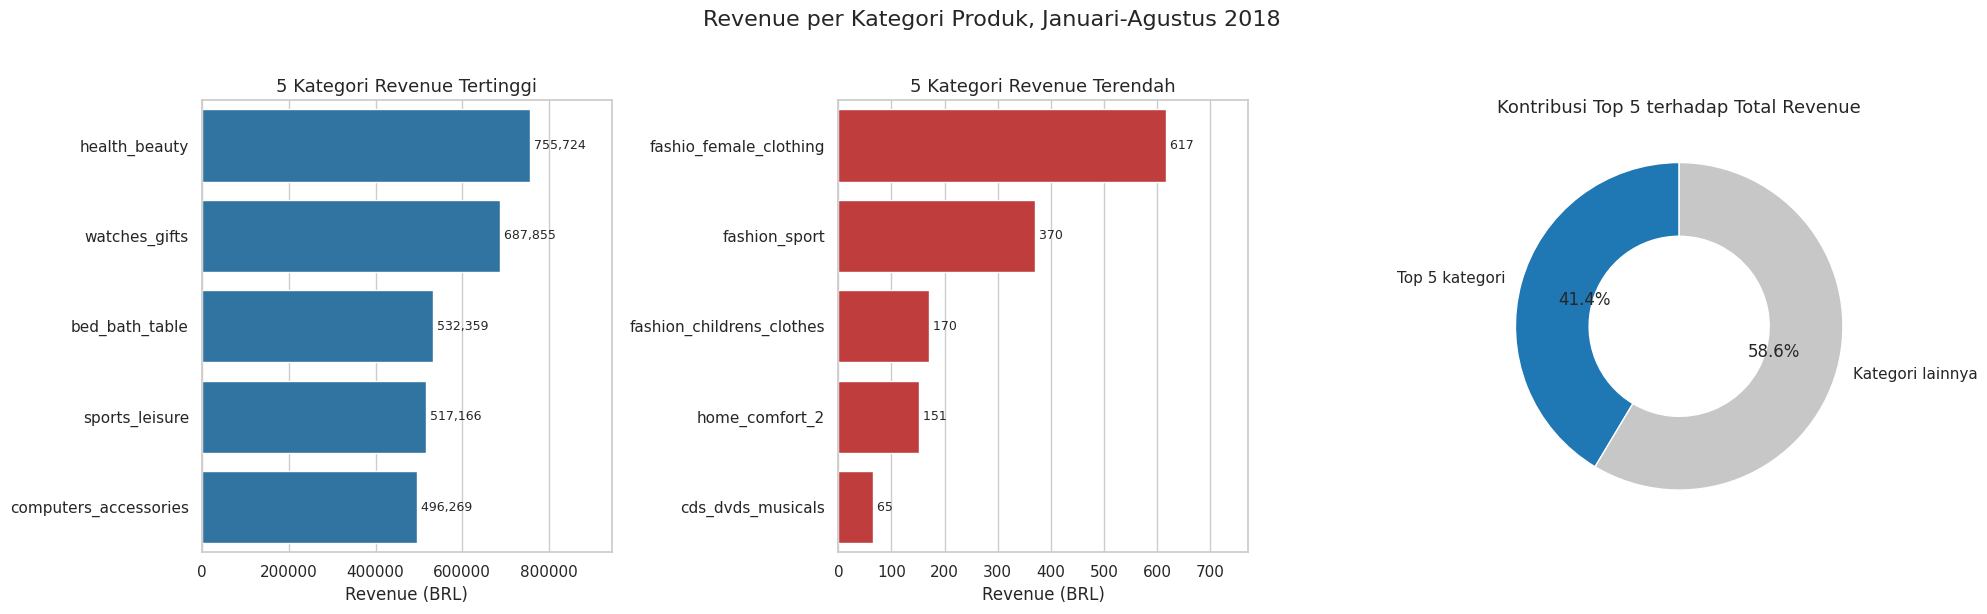

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
fig, ax = plt.subplots(1, 3, figsize=(20, 6))

# 1. Top 5 kategori
top5 = category_revenue_df.head(5)
sns.barplot(data=top5, x='revenue', y='product_category_name_english', color='#1f77b4', ax=ax[0])
ax[0].set_title('5 Kategori Revenue Tertinggi', fontsize=13)
ax[0].set_xlabel('Revenue (BRL)')
ax[0].set_ylabel('')
for i, v in enumerate(top5['revenue']):
    ax[0].text(v, i, f' {v:,.0f}', va='center', fontsize=9)
ax[0].set_xlim(0, top5['revenue'].max() * 1.25)

# 2. Bottom 5 kategori
bottom5 = category_revenue_df.tail(5).sort_values('revenue', ascending=False)
sns.barplot(data=bottom5, x='revenue', y='product_category_name_english', color='#d62728', ax=ax[1])
ax[1].set_title('5 Kategori Revenue Terendah', fontsize=13)
ax[1].set_xlabel('Revenue (BRL)')
ax[1].set_ylabel('')
for i, v in enumerate(bottom5['revenue']):
    ax[1].text(v, i, f' {v:,.0f}', va='center', fontsize=9)
ax[1].set_xlim(0, bottom5['revenue'].max() * 1.25)

# 3. Proporsi top 5 terhadap total revenue
sizes = [top5_share, 100 - top5_share]
ax[2].pie(sizes, labels=['Top 5 kategori', 'Kategori lainnya'], autopct='%1.1f%%',
          colors=['#1f77b4', '#c7c7c7'], startangle=90, wedgeprops={'width': 0.45})
ax[2].set_title('Kontribusi Top 5 terhadap Total Revenue', fontsize=13)

plt.suptitle('Revenue per Kategori Produk, Januari-Agustus 2018', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

### Pertanyaan 2:

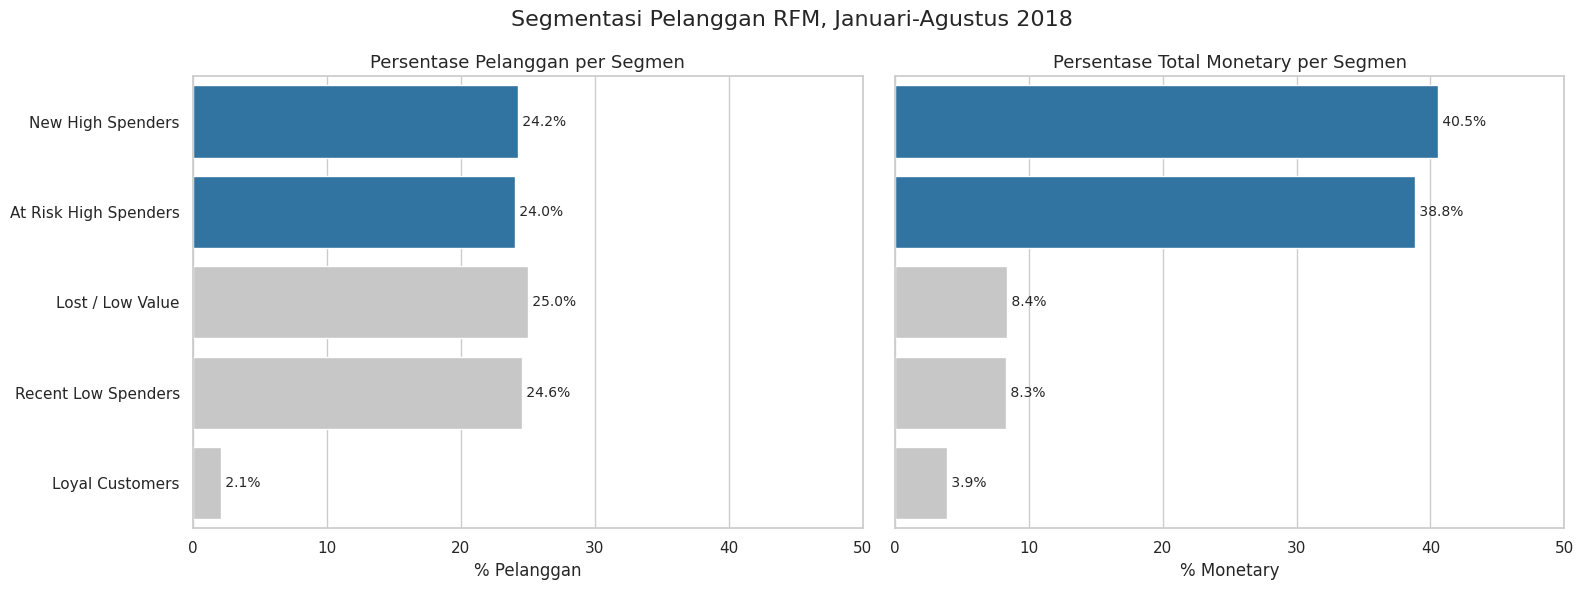

In [8]:
order = segment_df.sort_values('pct_monetary', ascending=False)['segment'].tolist()
palette = {s: ('#1f77b4' if s in order[:2] else '#c7c7c7') for s in order}

fig, ax = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

sns.barplot(data=segment_df, x='pct_customers', y='segment', order=order,
            hue='segment', palette=palette, legend=False, ax=ax[0])
ax[0].set_title('Persentase Pelanggan per Segmen', fontsize=13)
ax[0].set_xlabel('% Pelanggan')
ax[0].set_ylabel('')

sns.barplot(data=segment_df, x='pct_monetary', y='segment', order=order,
            hue='segment', palette=palette, legend=False, ax=ax[1])
ax[1].set_title('Persentase Total Monetary per Segmen', fontsize=13)
ax[1].set_xlabel('% Monetary')
ax[1].set_ylabel('')

for a, col in zip(ax, ['pct_customers', 'pct_monetary']):
    for i, seg in enumerate(order):
        v = segment_df.loc[segment_df['segment'] == seg, col].values[0]
        a.text(v, i, f' {v:.1f}%', va='center', fontsize=10)
    a.set_xlim(0, 50)

plt.suptitle('Segmentasi Pelanggan RFM, Januari-Agustus 2018', fontsize=16)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)

**Pertanyaan Bisnis 1 :**
- `health_beauty` adalah kategori dengan revenue tertinggi (10,47% dari total), disusul `watches_gifts` dan `bed_bath_table`.
- Lima kategori teratas menyumbang 41,41% total revenue, sedangkan kategori terendah (mis. `cds_dvds_musicals` senilai 65,00) nyaris tidak berkontribusi.

**Pertanyaan Bisnis 2 :**
- New High Spenders (40,54%) dan At Risk High Spenders (38,85%) bersama menyumbang sekitar 79% total monetary dari sekitar 48% pelanggan.
- Lost / Low Value adalah segmen terbesar dari sisi jumlah pelanggan (25,05%) tetapi hanya menyumbang 8,39% monetary.

## Analisis Lanjutan (Opsional)

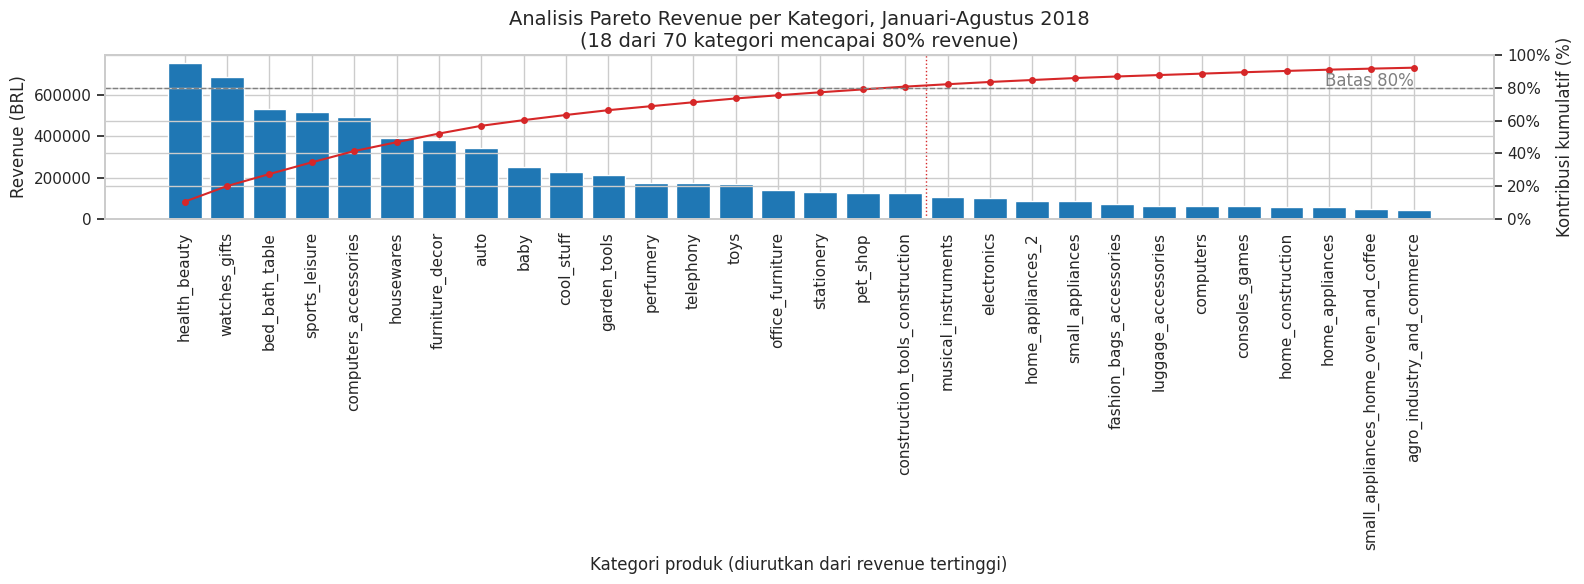

In [9]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Tampilkan 30 kategori teratas agar label terbaca
pareto_df = category_revenue_df.head(30)

fig, ax1 = plt.subplots(figsize=(16, 6))

# Bar: revenue per kategori
ax1.bar(pareto_df['product_category_name_english'], pareto_df['revenue'], color='#1f77b4')
ax1.set_ylabel('Revenue (BRL)')
ax1.set_xlabel('Kategori produk (diurutkan dari revenue tertinggi)')
ax1.tick_params(axis='x', rotation=90)

# Garis: persentase kumulatif
ax2 = ax1.twinx()
ax2.plot(pareto_df['product_category_name_english'], pareto_df['cum_pct'],
         color='#d62728', marker='o', markersize=4)
ax2.axhline(80, color='gray', linestyle='--', linewidth=1)
ax2.text(len(pareto_df) - 1, 81.5, 'Batas 80%', ha='right', color='gray')
ax2.set_ylabel('Kontribusi kumulatif (%)')
ax2.set_ylim(0, 100)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())

# Penanda kategori ke-n_80 (titik tercapainya 80% revenue)
ax1.axvline(n_80 - 0.5, color='#d62728', linestyle=':', linewidth=1)

plt.title(f'Analisis Pareto Revenue per Kategori, Januari-Agustus 2018\n'
          f'({n_80} dari {category_revenue_df.shape[0]} kategori mencapai 80% revenue)', fontsize=14)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Analisis lanjutan yang diterapkan adalah **RFM Analysis** dengan manual grouping (Frequency) dan binning kuartil (Recency dan Monetary) untuk Pertanyaan 2, serta **analisis Pareto** untuk Pertanyaan 1.
- Berdasarkan kurva Pareto, 18 dari 70 kategori (sekitar 26%) sudah menyumbang 80% total revenue, sehingga pendapatan sangat terkonsentrasi pada sebagian kecil kategori.
- Kategori di luar kelompok tersebut berkontribusi kecil secara individu, sehingga pengelolaan stok dan promosi bisa difokuskan pada kategori teratas.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Selama Januari-Agustus 2018, kategori `health_beauty` menghasilkan revenue tertinggi (755.724,50 atau 10,47% dari total), disusul `watches_gifts` dan `bed_bath_table`, sedangkan kategori terendah adalah `cds_dvds_musicals` (65,00). Lima kategori teratas menyumbang 41,41% total revenue, dan hanya 18 dari 70 kategori yang dibutuhkan untuk mencapai 80% revenue, sehingga pendapatan sangat terkonsentrasi pada sebagian kecil kategori.

- **Conclusion pertanyaan 2:** Dari 51.612 pelanggan pada Januari-Agustus 2018, sekitar 97,9% hanya bertransaksi sekali. Segmen New High Spenders (40,54%) dan At Risk High Spenders (38,85%) bersama menyumbang sekitar 79% total monetary dari sekitar 48% pelanggan, sehingga keduanya menjadi segmen prioritas untuk program retensi. Segmen Lost / Low Value adalah yang terbesar dari sisi jumlah pelanggan (25,05%) tetapi hanya menyumbang 8,39% monetary.

**Rekomendasi Action Item:**
- Prioritaskan promosi, penjaminan stok, dan pengembangan produk pada lima kategori teratas (`health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, `computers_accessories`), karena menyumbang 41,41% revenue.
- Evaluasi kategori dengan revenue sangat rendah (mis. `cds_dvds_musicals` dan kategori fashion), apakah perlu dipertahankan, digabung dalam bundel promo, atau dikurangi stoknya.
- Jalankan program retensi untuk New High Spenders agar melakukan pembelian kedua, misalnya voucher pembelian ulang atau rekomendasi produk terkait.
- Aktifkan kembali At Risk High Spenders dengan penawaran personal (win-back campaign) karena sudah lama tidak berbelanja tetapi bernilai tinggi.
- Pertahankan Loyal Customers dengan program loyalitas, karena rata-rata belanjanya tertinggi walau jumlahnya kecil.